# Ensemble: Pareto -> nesting -> final candidates -> candidate events -> logistic regression -> validation -> test -> NGRIP

Warming only. Tolerance 0.5 kyr everywhere (matching and candidate grouping), one-to-one matching (ammonyte `evaluate_detection`).
Data: NOISIER split (`noisier_data/train_test_split_data/`). Detectors: **ruptures** (all algorithms pooled: Pelt, KernelCPD, Binseg, BottomUp; ONE Pareto front, ONE support feature), the **KS** test and **LERM** (+ KernelCPD on the Fisher information, finalized study `optuna_search_lerm/results_lerm_kcpd`). ruptures keeps its whole Pareto front (rule `support`); KS and LERM keep ONE config each (best train F1, rule `single`). LERM configs = trial parameters + the trial's best penalty multiplier `k`; ~20 s per series, cached in `results/cache`.

| split | used for |
|---|---|
| train | Pareto fronts / nesting / final configs, fit logistic regression |
| validation | choose method combination, C, class weight, probability threshold (no refit on validation) |
| test | scored **once**, frozen pipeline |
| NGRIP | frozen pipeline, nothing changed |

1. Pareto front per detector (no further filter) -> 2. nesting within each detector -> 3. final configs per detector, rule per detector (+ diversity as a diagnostic only)
4. candidate-event table -> 5. logistic regression (train) -> 6. validation: combination + C + class weight + threshold
7. freeze -> 8. test once -> 9. NGRIP

In [1]:
import os, sys, json
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from paretoset import paretoset
from scipy.spatial.distance import pdist, squareform
from sklearn.linear_model import LogisticRegression
sys.path.insert(0, os.getcwd())
import detectors, ensemble_utils as eu

SPLIT_DIR = os.path.normpath(os.path.join(os.getcwd(), "..", "..", "noisier_data", "train_test_split_data"))
TRAIN_PATH, VAL_PATH, TEST_PATH = (os.path.join(SPLIT_DIR, f"{s}.npz") for s in ("train", "validation", "test"))
for _p in (TRAIN_PATH, VAL_PATH, TEST_PATH):
    assert os.path.exists(_p), _p
TOL = eu.TOLERANCE
RESULTS = "results"
CACHE = os.path.join(RESULTS, "cache"); os.makedirs(CACHE, exist_ok=True)

# ---- predefined choices (fixed BEFORE looking at validation) ----
# detectors and the rule for each: "support" = keep the whole Pareto front, ONE feature = fraction of its configs detecting a candidate;
# "single" = only the best-train-F1 config of the front (feature is then 0/1)
RULE = {"ruptures": "support", "KS": "single", "LERM": "single"}   # step 3
USE = list(RULE)
assert set(RULE.values()) <= {"support", "single"}
NEST_THRESH = 0.90       # step 2: a family is 'nested' if mean containment of the smaller detection set in the larger >= this
C_GRID = [0.01, 0.1, 1, 10, 100]            # step 6: L2 strength (sklearn C), chosen on validation
CLASS_WEIGHTS = [None, "balanced"]          # step 6: chosen on validation
# step 6 combinations: every single detector, every pair, and all detectors together

## Step 1: Pareto front (train precision vs recall, warming) separately for each detector

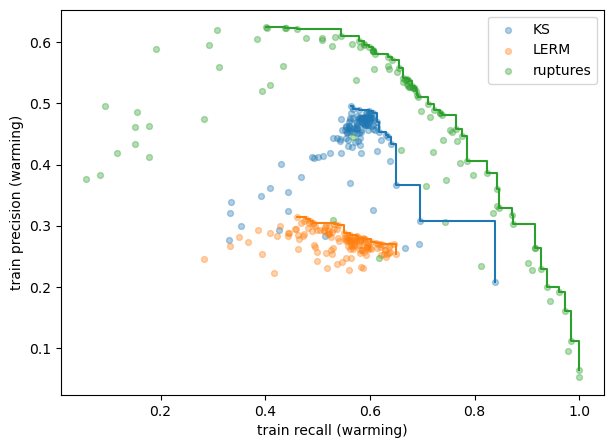

,trials,front,best_F1
detector,,,
KS,131,13,0.430
LERM,135,18,0.363
ruptures,110,42,0.569


In [2]:
trials = pd.concat([detectors.load_trials(k) for k in detectors.SOURCES], ignore_index=True)
fronts = pd.concat([g[paretoset(g[["R", "P"]], sense=["max", "max"])] for _, g in trials.groupby("detector")]).sort_values(["detector", "R"])
retained = fronts[fronts["detector"].isin(USE)].copy()      # the Pareto front itself, no further filter
DETECTORS = sorted(retained["detector"].unique())

fig, ax = plt.subplots(figsize=(7, 5))
for m, g in trials.groupby("detector"):
    ax.scatter(g["R"], g["P"], s=18, alpha=.35, label=m)
    f = fronts[fronts["detector"] == m]; ax.step(f["R"], f["P"], where="post", lw=1.5)
ax.set_xlabel("train recall (warming)"); ax.set_ylabel("train precision (warming)"); ax.legend(); plt.show()
pd.DataFrame({"trials": trials.groupby("detector").size(), "front": fronts.groupby("detector").size(),
              "best_F1": fronts.groupby("detector")["F1"].max().round(3)})

## Step 2: nesting within each detector (train)

Is the detection set of one config approximately contained in another's (within the tolerance)? Computed per series for every pair of configs of a family (same detector and cost), then averaged. Nested = the configs differ mainly in strictness.

In [3]:
# configs the rule keeps: the whole front for "support" detectors, the best-train-F1 config for "single" ones (used again in step 3)
single = retained["detector"].map(RULE) == "single"
nest = pd.concat([retained[~single], retained.loc[retained[single].groupby("detector")["F1"].idxmax()]])
configs = nest.set_index("cfg")["params"].to_dict()
det_tr, gt_tr = eu.run_split(TRAIN_PATH, configs, os.path.join(CACHE, "train_dets.pkl"))
print(len(det_tr), "train series;", sum(len(g) for g in gt_tr), "true warming events")

rows = []
for fam, g in nest.groupby("family"):
    ids = list(g["cfg"])
    if len(ids) < 2:
        rows.append(dict(detector=g["detector"].iloc[0], family=fam, n_configs=1)); continue
    vals = [np.nanmean([eu.nesting(d[a], d[b], TOL) for d in det_tr]) for a, b in combinations(ids, 2)]
    rows.append(dict(detector=g["detector"].iloc[0], family=fam, n_configs=len(ids), mean_containment=round(np.mean(vals), 3),
                     min_containment=round(min(vals), 3), nested=bool(np.mean(vals) >= NEST_THRESH)))
pd.DataFrame(rows).set_index("family")

60 train series; 1459 true warming events


,detector,n_configs,mean_containment,min_containment,nested
family,,,,,
Binseg_l1,ruptures,1,NaN,NaN,NaN
Binseg_l2,ruptures,1,NaN,NaN,NaN
KS,KS,1,NaN,NaN,NaN
KernelCPD_linear,ruptures,34,0.976,0.882,True
KernelCPD_rbf,ruptures,1,NaN,NaN,NaN
LERM,LERM,1,NaN,NaN,NaN
Pelt_l2,ruptures,4,0.993,0.966,True
Pelt_mahalanobis,ruptures,1,NaN,NaN,NaN


## Step 3: final candidate(s) per detector

`RULE` is set per detector in the first cell.

- `"single"`: one config for the detector (best train F1). Support is then 0/1.
- `"support"`: keep all Pareto-front configs of a detector and combine them into ONE detector-level feature, `S_m(e) = (# configs of detector m detecting e) / (# retained configs of m)`, so detectors with more configs get no extra weight.

Diversity between detectors is only a **diagnostic** here (shared/unique true detections and false alarms); nothing is dropped because of it.

,n_configs,best_F1
detector,,
KS,1,0.430
LERM,1,0.363
ruptures,42,0.569


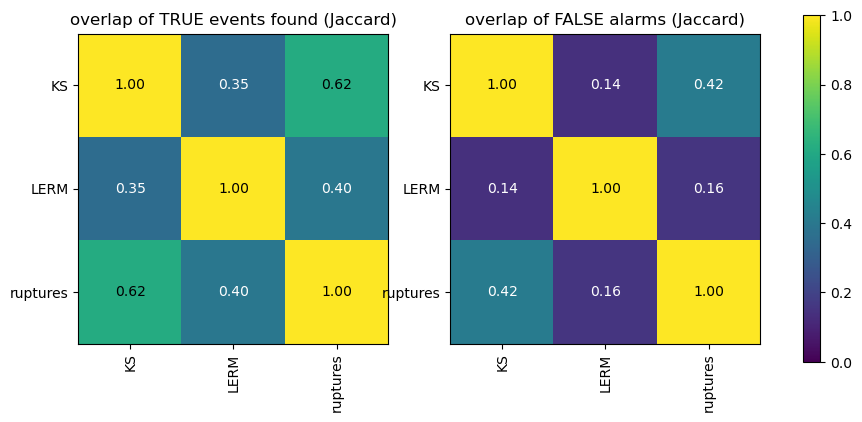

,true_found,false_alarms,unique_true,unique_false,precision
KS,691,1520,94,584,0.313
LERM,551,1794,135,1262,0.235
ruptures,766,1239,120,299,0.382


In [4]:
retained = nest                                                   # configs kept by the per-detector rule
configs = retained.set_index("cfg")["params"].to_dict()
det_tr = [{c: d[c] for c in configs} for d in det_tr]            # drop detections of configs the rule removed
group_of = retained.set_index("cfg")["detector"].to_dict()      # feature group = detector
display(retained.groupby("detector").agg(n_configs=("cfg", "size"), best_F1=("F1", "max")).round(3))

# diversity diagnostic (train): a detector 'detects' a candidate if >= half of its configs do
tab_all = eu.build_table(det_tr, gt_tr, group_of, TOL)
D = (tab_all.filter(like="support_") >= 0.5).rename(columns=lambda c: c[len("support_"):])
y = tab_all["label"].values
alone = D.sum(axis=1) == 1
summary = pd.DataFrame({"true_found": D[y == 1].sum(), "false_alarms": D[y == 0].sum(),
                        "unique_true": D[alone & (y == 1)].sum(), "unique_false": D[alone & (y == 0)].sum()})
summary["precision"] = (summary.true_found / (summary.true_found + summary.false_alarms)).round(3)
jaccard = lambda M: pd.DataFrame(1 - squareform(pdist(M.T, "jaccard")), index=D.columns, columns=D.columns)
Jt, Jf = jaccard(D[y == 1].values), jaccard(D[y == 0].values)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, J, t in zip(axs, (Jt, Jf), ("overlap of TRUE events found (Jaccard)", "overlap of FALSE alarms (Jaccard)")):
    im = ax.imshow(J.values, vmin=0, vmax=1, cmap="viridis"); ax.set_title(t)
    ax.set_xticks(range(len(D.columns)), D.columns, rotation=90); ax.set_yticks(range(len(D.columns)), D.columns)
    for i in range(len(J)):                                        # value of each square
        for j in range(len(J)):
            ax.text(j, i, f"{J.values[i, j]:.2f}", ha="center", va="center", color="white" if J.values[i, j] < .6 else "black")
fig.colorbar(im, ax=axs); plt.show()
summary

## Step 4: candidate-event windows

Detections of the configs of the selected detectors are pooled per series; a new candidate starts when a detection is more than 0.5 kyr after the first detection of the current one; candidate time = median detection time. Each detection belongs to exactly one candidate. A candidate is true if it matches a true event one-to-one. True events with no candidate are never rows, they count as FN (recall is always vs ALL true events), so the **candidate recall ceiling** is the best recall any threshold can reach.

The candidate set depends on which detectors are combined, so the tables are rebuilt for every combination (`tables`).

In [5]:
def tables(dets, gts, combo):
    """Candidate table using only the configs of the detectors in `combo`."""
    sub = [{c: v for c, v in d.items() if group_of[c] in combo} for d in dets]
    return eu.build_table(sub, gts, {c: g for c, g in group_of.items() if g in combo}, TOL)

n_true_tr = sum(len(g) for g in gt_tr)
tab = tables(det_tr, gt_tr, tuple(DETECTORS))
print(f"train, all detectors: {len(tab)} candidates, {tab['label'].sum()} true ({tab['label'].mean():.0%}) of {n_true_tr} true events -> candidate recall ceiling {tab['label'].sum() / n_true_tr:.3f}")
single = {cid: np.mean([eu.match_flags(d[cid], g, TOL).sum() / max(len(g), 1) for d, g in zip(det_tr, gt_tr)]) for cid in configs}
print("best single-config mean recall:", round(max(single.values()), 3), "(", max(single, key=single.get), ")")
tab.head()

train, all detectors: 10338 candidates, 1451 true (14%) of 1459 true events -> candidate recall ceiling 0.995


best single-config mean recall: 1.0 ( KernelCPD|linear|t37 )


,series,pos,label,support_KS,support_LERM,support_ruptures
0,0,0.74,0,0.0,0.0,0.071429
1,0,1.18,0,0.0,0.0,0.261905
2,0,1.66,0,0.0,0.0,0.119048
3,0,2.38,0,0.0,0.0,0.071429
4,0,3.26,0,0.0,0.0,0.690476


## Step 5: logistic regression on the training candidates

One row per candidate, features = detector-level support, label = true/false event. L2-regularised `LogisticRegression`; the output is the probability that a candidate is a real event. Train fits only. C and class weight are chosen with the other validation choices in step 6 (no cross-validation, the validation set is used instead).

In [6]:
FEATURES = [f"support_{d}" for d in DETECTORS]
lr_all = LogisticRegression(max_iter=1000).fit(tab[FEATURES], tab["label"])      # default C=1, only to inspect the weights
pd.Series(lr_all.coef_[0], index=DETECTORS).round(3).to_frame("coefficient (all detectors, C=1)")

,"coefficient (all detectors, C=1)"
KS,0.234
LERM,0.434
ruptures,2.606


## Step 6: validation: method combination + C + class weight + probability threshold

For every predefined combination (each detector alone, each pair, all together) and every (C, class weight): fit on train, score validation, take the threshold with the best **event-level F1** (one-to-one matching, recall vs all true events). The combination, C, class weight and threshold with the best validation F1 are selected. No refit on validation.

In [7]:
det_va, gt_va = eu.run_split(VAL_PATH, configs, os.path.join(CACHE, "validation_dets.pkl"))
n_true_va = sum(len(g) for g in gt_va)
COMBOS = list(dict.fromkeys([c for r in (1, 2) for c in combinations(DETECTORS, r)] + [tuple(DETECTORS)]))
rows = []
for combo in COMBOS:
    tr, va = tables(det_tr, gt_tr, combo), tables(det_va, gt_va, combo)
    feat = [f"support_{d}" for d in combo]
    for C in C_GRID:
        for cw in CLASS_WEIGHTS:
            lr = LogisticRegression(C=C, class_weight=cw, max_iter=1000).fit(tr[feat], tr["label"])
            curve = eu.event_curve(va, lr.predict_proba(va[feat])[:, 1], gt_va, TOL)
            b = curve.loc[curve["f1"].idxmax()]
            rows.append(dict(combo="+".join(combo), C=C, class_weight=str(cw), threshold=b["threshold"], TP=int(b["TP"]), FP=int(b["FP"]),
                             FN=int(b["FN"]), precision=b["precision"], recall=b["recall"], f1=b["f1"],
                             cand_recall=va["label"].sum() / n_true_va))
val_results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
print(len(COMBOS), "combinations x", len(C_GRID) * len(CLASS_WEIGHTS), "(C, class weight) settings")
display(val_results.loc[val_results.groupby("combo")["f1"].idxmax()].sort_values("f1", ascending=False).round(3).set_index("combo"))

7 combinations x 10 (C, class weight) settings


,C,class_weight,threshold,TP,FP,FN,precision,recall,f1,cand_recall
combo,,,,,,,,,,
LERM+ruptures,0.01,balanced,0.54,483,485,286,0.499,0.628,0.556,0.992
KS+LERM+ruptures,100.00,balanced,0.57,486,494,283,0.496,0.632,0.556,0.992
KS+ruptures,0.10,balanced,0.54,499,530,270,0.485,0.649,0.555,0.992
ruptures,10.00,balanced,0.58,472,467,297,0.503,0.614,0.553,0.992
KS+LERM,1.00,balanced,0.33,398,578,371,0.408,0.518,0.456,0.730
KS,0.10,None,0.02,395,580,374,0.405,0.514,0.453,0.514
LERM,0.01,balanced,0.02,378,795,391,0.322,0.492,0.389,0.492


selected (validation):
combo           LERM+ruptures
C                        0.01
class_weight         balanced
threshold                0.54
TP                        483
FP                        485
FN                        286
precision            0.498967
recall               0.628088
f1                   0.556131
cand_recall          0.992198
Name: 0, dtype: object


,coefficient
LERM,0.418
ruptures,1.985


,accepted,TP,FP,FN,precision,recall,f1,chosen
threshold,,,,,,,,
0.05,5107,763,4344,6,0.149,0.992,0.260,False
0.10,5107,763,4344,6,0.149,0.992,0.260,False
0.15,5107,763,4344,6,0.149,0.992,0.260,False
0.20,5107,763,4344,6,0.149,0.992,0.260,False
0.25,5107,763,4344,6,0.149,0.992,0.260,False
0.30,5107,763,4344,6,0.149,0.992,0.260,False
0.35,3169,710,2459,59,0.224,0.923,0.361,False
0.40,2285,636,1649,133,0.278,0.827,0.417,False
0.45,1629,587,1042,182,0.360,0.763,0.490,False


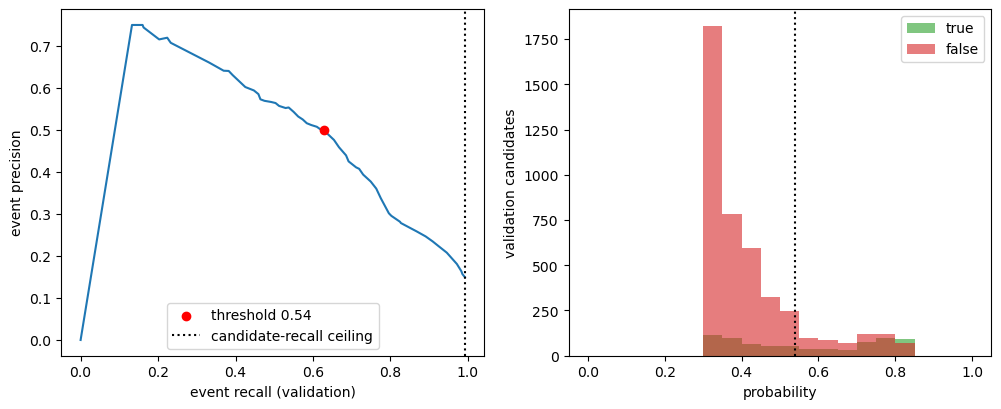

In [8]:
best = val_results.iloc[0]
SEL = tuple(best["combo"].split("+")); C_SEL = float(best["C"]); CW_SEL = None if best["class_weight"] == "None" else best["class_weight"]
THRESHOLD = float(best["threshold"]); FEAT = [f"support_{d}" for d in SEL]
print("selected (validation):"); print(best)
tab_tr, tab_va = tables(det_tr, gt_tr, SEL), tables(det_va, gt_va, SEL)
lr = LogisticRegression(C=C_SEL, class_weight=CW_SEL, max_iter=1000).fit(tab_tr[FEAT], tab_tr["label"])   # train only
p_va = lr.predict_proba(tab_va[FEAT])[:, 1]
display(pd.Series(lr.coef_[0], index=SEL).round(3).to_frame("coefficient"))

# what each threshold does on validation (TP / FP / FN), plus the probability distribution of true vs false candidates
grid = sorted(set(np.round(np.arange(0.05, 0.96, 0.05), 2)) | {round(THRESHOLD, 3)})
rows = []
for t in grid:
    tp, fp, fn = eu.event_counts(tab_va, gt_va, p_va >= t, TOL)
    pr, rc = tp / max(tp + fp, 1), tp / (tp + fn)
    rows.append(dict(threshold=t, accepted=int((p_va >= t).sum()), TP=tp, FP=fp, FN=fn, precision=pr, recall=rc,
                     f1=2 * pr * rc / (pr + rc) if tp else 0.0, chosen=abs(t - round(THRESHOLD, 3)) < 1e-9))
display(pd.DataFrame(rows).set_index("threshold").round(3))
curve = eu.event_curve(tab_va, p_va, gt_va, TOL)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].plot(curve["recall"], curve["precision"]); axs[0].scatter(best["recall"], best["precision"], c="red", zorder=3, label=f"threshold {THRESHOLD:.2f}")
axs[0].axvline(best["cand_recall"], ls=":", c="k", label="candidate-recall ceiling"); axs[0].set_xlabel("event recall (validation)"); axs[0].set_ylabel("event precision"); axs[0].legend()
bins = np.linspace(0, 1, 21)
axs[1].hist(p_va[tab_va.label == 1], bins=bins, alpha=.6, color="tab:green", label="true"); axs[1].hist(p_va[tab_va.label == 0], bins=bins, alpha=.6, color="tab:red", label="false")
axs[1].axvline(THRESHOLD, c="k", ls=":"); axs[1].set_xlabel("probability"); axs[1].set_ylabel("validation candidates"); axs[1].legend(); plt.show()

## Step 6b: check, does the logistic regression beat picking ONE ruptures config? (validation, whole precision-recall curve)

Each ruptures config of the Pareto front is a different precision/recall trade-off, so scoring them all on validation draws the best curve you can get with ONE config and no ensemble. The logistic regression (and the raw `support_ruptures` score, no model) must lie above it, otherwise the ensemble adds nothing over tuning one config. Threshold-free summary: average precision (AP) of the event-level curve, recall always vs ALL true events. Nothing is refit or changed here.

validation, event level (recall vs all true events)


,max F1,AP (area under P-R)
best single ruptures config / front,0.552,0.491
logistic regression (LERM+ruptures),0.556,0.527
support_ruptures alone,0.551,0.505


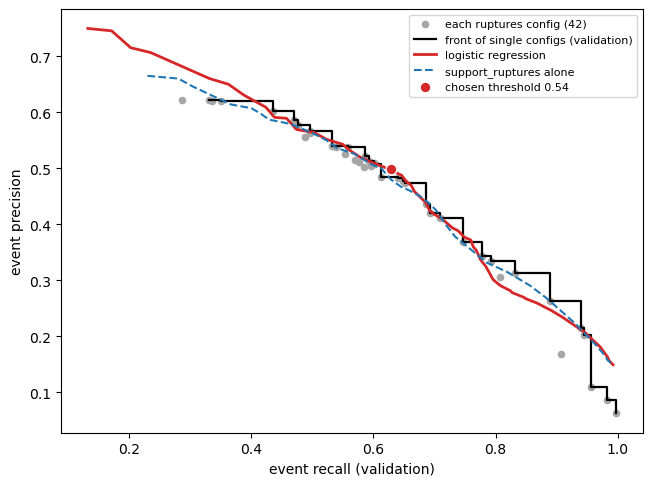

In [9]:
from sklearn.metrics import auc
# (1) every ruptures config on VALIDATION: pooled event-level precision/recall (one point per config)
rup = [c for c in configs if group_of[c] == "ruptures"]
pts = []
for c in rup:
    tp, fp, fn = eu.pooled_counts([d[c] for d in det_va], gt_va, TOL)
    pts.append(dict(cfg=c, P=tp / max(tp + fp, 1), R=tp / (tp + fn)))
pts = pd.DataFrame(pts); pts["F1"] = 2 * pts.P * pts.R / (pts.P + pts.R)
front_va = pts[paretoset(pts[["R", "P"]], sense=["max", "max"])].sort_values("R")

# (2) full curves of the logistic regression score and of support_ruptures alone (thresholds = score quantiles, scores can be bunched)
def curve_of(score):
    th = np.unique(np.quantile(score, np.linspace(0, 1, 121)))
    return eu.event_curve(tab_va, score, gt_va, TOL, thresholds=th).sort_values("recall")
ap = lambda c: auc(np.r_[0, c["recall"]], np.r_[c["precision"].iloc[0], c["precision"]])   # area under precision-recall (recall vs ALL true events)
cur_lr, cur_sup = curve_of(p_va), curve_of(tab_va["support_ruptures"].values)
print("validation, event level (recall vs all true events)")
display(pd.DataFrame({"max F1": [pts.F1.max(), cur_lr.f1.max(), cur_sup.f1.max()],
                      "AP (area under P-R)": [auc(np.r_[0, front_va.R], np.r_[front_va.P.iloc[0], front_va.P]), ap(cur_lr), ap(cur_sup)]},
                     index=["best single ruptures config / front", f"logistic regression ({'+'.join(SEL)})", "support_ruptures alone"]).round(3))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(pts.R, pts.P, s=20, c="0.65", label=f"each ruptures config ({len(pts)})")
ax.step(front_va.R, front_va.P, where="post", c="k", lw=1.6, label="front of single configs (validation)")
ax.plot(cur_lr.recall, cur_lr.precision, c="tab:red", lw=2, label="logistic regression")
ax.plot(cur_sup.recall, cur_sup.precision, c="tab:blue", lw=1.5, ls="--", label="support_ruptures alone")
ax.scatter(best["recall"], best["precision"], c="tab:red", s=60, zorder=4, edgecolor="w", label=f"chosen threshold {THRESHOLD:.2f}")
ax.set_xlabel("event recall (validation)"); ax.set_ylabel("event precision"); ax.legend(fontsize=8); plt.show()

## Step 6c: is the score better than random, and is the threshold meaningful? (validation, nothing refit)

1. **ROC-AUC** of the logistic-regression score at candidate level (true vs false candidate): 0.5 = random ranking, 1 = perfect. With a 95% bootstrap CI that resamples whole series (candidates of one series are not independent). Compared with `support_ruptures` alone.
2. **Threshold curve**: event-level F1 for every threshold. A broad plateau around the chosen value means the threshold is not a lucky number; a sharp spike would mean it is.
3. **Threshold bootstrap**: re-choose the best-F1 threshold on resampled validation series; its spread says how well determined the threshold is.
4. **Random-ranking baseline**: accept the same number of candidates but pick them at random; the F1 must be far below the chosen one.

,ROC-AUC (validation),95% CI low,95% CI high
logistic regression (LERM+ruptures),0.746,0.716,0.785
support_ruptures alone,0.748,0.719,0.781


chosen threshold 0.54; bootstrap best threshold: median 0.55, 5-95% range 0.53-0.62
thresholds within 0.01 F1 of the best: 0.53-0.61


F1 at chosen threshold 0.556; random choice of the same 968 candidates: 0.251 (max of 100 draws 0.282)


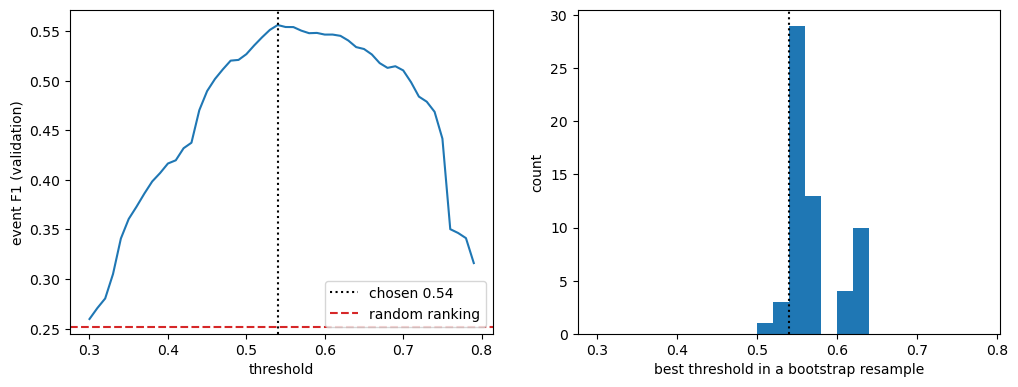

In [10]:
from sklearn.metrics import roc_auc_score
rs = np.random.default_rng(0)
yv, sup_v = tab_va["label"].values, tab_va["support_ruptures"].values
n_ser = len(gt_va)
rows_by_series = [np.where(tab_va["series"].values == s)[0] for s in range(n_ser)]

def resample(idx):
    """Validation candidates/truth of the resampled series (re-indexed 0..n-1) and the row positions used."""
    rows = np.concatenate([rows_by_series[s] for s in idx])
    tb = tab_va.iloc[rows].copy()
    tb["series"] = np.concatenate([np.full(len(rows_by_series[s]), j) for j, s in enumerate(idx)])
    return tb, [gt_va[s] for s in idx], rows

# 1) ROC-AUC with series-bootstrap CI (candidate level: true vs false candidate)
aucs = []
for _ in range(200):
    _, _, r = resample(rs.integers(0, n_ser, n_ser))
    if yv[r].min() != yv[r].max():
        aucs.append((roc_auc_score(yv[r], p_va[r]), roc_auc_score(yv[r], sup_v[r])))
aucs = np.array(aucs)
display(pd.DataFrame({"ROC-AUC (validation)": [roc_auc_score(yv, p_va), roc_auc_score(yv, sup_v)],
                      "95% CI low": np.percentile(aucs, 2.5, axis=0), "95% CI high": np.percentile(aucs, 97.5, axis=0)},
                     index=[f"logistic regression ({'+'.join(SEL)})", "support_ruptures alone"]).round(3))

# 2) event-level F1 for every threshold on a fine grid
fine = np.round(np.arange(0.30, 0.80, 0.01), 2)
cf = eu.event_curve(tab_va, p_va, gt_va, TOL, thresholds=fine)

# 3) bootstrap of the best-F1 threshold (resample validation series, re-choose the threshold each time)
best_t = []
for _ in range(60):
    tb, gb, r = resample(rs.integers(0, n_ser, n_ser))
    c = eu.event_curve(tb, p_va[r], gb, TOL, thresholds=fine)
    best_t.append(c.loc[c["f1"].idxmax(), "threshold"])
best_t = np.array(best_t)
print(f"chosen threshold {THRESHOLD:.2f}; bootstrap best threshold: median {np.median(best_t):.2f}, 5-95% range {np.percentile(best_t, 5):.2f}-{np.percentile(best_t, 95):.2f}")
near = cf[cf["f1"] >= cf["f1"].max() - 0.01]["threshold"]
print(f"thresholds within 0.01 F1 of the best: {near.min():.2f}-{near.max():.2f}")

# 4) random-ranking baseline: accept as many candidates as the chosen threshold does, but at random
n_acc = int((p_va >= THRESHOLD).sum())
rand_f1 = []
for _ in range(100):
    acc = np.zeros(len(tab_va), bool); acc[rs.choice(len(tab_va), n_acc, replace=False)] = True
    tp, fp, fn = eu.event_counts(tab_va, gt_va, acc, TOL)
    rand_f1.append(2 * tp / (2 * tp + fp + fn))
print(f"F1 at chosen threshold {best['f1']:.3f}; random choice of the same {n_acc} candidates: {np.mean(rand_f1):.3f} (max of 100 draws {np.max(rand_f1):.3f})")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].plot(cf["threshold"], cf["f1"]); axs[0].axvline(THRESHOLD, c="k", ls=":", label=f"chosen {THRESHOLD:.2f}")
axs[0].axhline(np.mean(rand_f1), c="tab:red", ls="--", label="random ranking"); axs[0].set_xlabel("threshold"); axs[0].set_ylabel("event F1 (validation)"); axs[0].legend()
axs[1].hist(best_t, bins=fine[::2]); axs[1].axvline(THRESHOLD, c="k", ls=":"); axs[1].set_xlabel("best threshold in a bootstrap resample"); axs[1].set_ylabel("count"); plt.show()

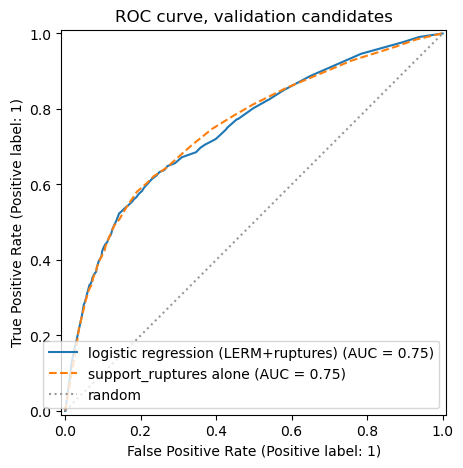

In [11]:
from sklearn.metrics import RocCurveDisplay
# ROC curve (candidate level, validation): logistic regression vs support_ruptures alone vs random
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(yv, p_va, name=f"logistic regression ({'+'.join(SEL)})", ax=ax)
RocCurveDisplay.from_predictions(yv, sup_v, name="support_ruptures alone", ax=ax, ls="--")
ax.plot([0, 1], [0, 1], c="0.6", ls=":", label="random"); ax.legend(loc="lower right"); ax.set_title("ROC curve, validation candidates"); plt.show()

,PR-AUC / AP (validation),95% CI low,95% CI high
logistic regression (LERM+ruptures),0.371,0.300,0.435
support_ruptures alone,0.361,0.291,0.420
random (= fraction of true candidates),0.149,NaN,NaN


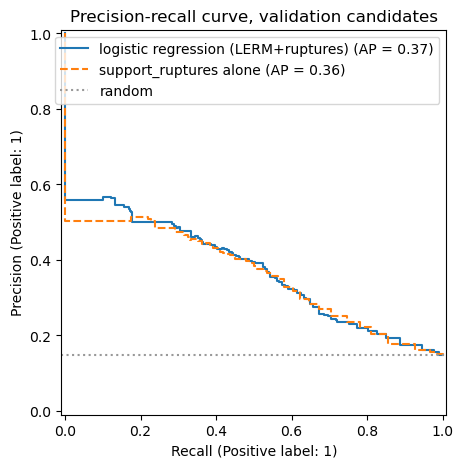

In [12]:
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
# candidate-level PR-AUC (average precision), validation; series bootstrap CI (same resamples logic as the ROC-AUC above)
rs_pr = np.random.default_rng(2)
aps = []
for _ in range(200):
    _, _, r = resample(rs_pr.integers(0, n_ser, n_ser))
    if yv[r].min() != yv[r].max():
        aps.append((average_precision_score(yv[r], p_va[r]), average_precision_score(yv[r], sup_v[r])))
aps = np.array(aps)
display(pd.DataFrame({"PR-AUC / AP (validation)": [average_precision_score(yv, p_va), average_precision_score(yv, sup_v), yv.mean()],
                      "95% CI low": [*np.percentile(aps, 2.5, axis=0), np.nan], "95% CI high": [*np.percentile(aps, 97.5, axis=0), np.nan]},
                     index=[f"logistic regression ({'+'.join(SEL)})", "support_ruptures alone", "random (= fraction of true candidates)"]).round(3))
fig, ax = plt.subplots(figsize=(5.5, 5))
PrecisionRecallDisplay.from_predictions(yv, p_va, name=f"logistic regression ({'+'.join(SEL)})", ax=ax)
PrecisionRecallDisplay.from_predictions(yv, sup_v, name="support_ruptures alone", ax=ax, ls="--")
ax.axhline(yv.mean(), c="0.6", ls=":", label="random"); ax.legend(loc="upper right"); ax.set_title("Precision-recall curve, validation candidates"); plt.show()

## Step 6d: ruptures only, better inputs for the logistic regression (validation, nothing in the frozen pipeline changes)

Steps 6b/6c showed that the pooled `support_ruptures` carries almost all the information and that LERM and KS add very little. So here only the **42 ruptures configs** of the front are used (same candidates, same label, same one-to-one matching) and the question is: can better inputs than the single pooled support fraction improve the ranking?

`eu.build_table` with one group per config gives a candidate x config 0/1 matrix, from which the inputs are derived:

| input set | idea |
|---|---|
| pooled support (current) | fraction of all 42 configs that detect the candidate |
| tiers: strict + loose | support inside the high-precision tier (train precision >= median) and inside the high-recall tier, as two features |
| strictness | train precision of the most precise config that detects the candidate (`max_P`), and the mean over detecting configs (`mean_P`) |
| per family | support inside each ruptures family (Pelt-l2, KernelCPD-linear, Binseg, ...) |
| tiers + strictness + n_fam | the above plus the number of families that detect the candidate |
| everything | all of them |

Features are standardized; `C` and class weight are chosen on validation by ROC-AUC (threshold free). Compared with ROC-AUC on validation, the event-level precision-recall curve, and a series bootstrap of the AUC difference to the current pooled support. A gain only counts if its CI excludes 0. The feature list was fixed before looking at the results.

In [13]:
rp_cfgs = [c for c in configs if group_of[c] == "ruptures"]
rp_info = retained.set_index("cfg").loc[rp_cfgs, ["family", "P", "R"]]      # train precision / recall of each front config
rp_strict = rp_info.index[rp_info["P"] >= rp_info["P"].median()]           # high-precision tier (low recall); the rest = high-recall tier
rp_fam_ids = {fam: list(ids) for fam, ids in rp_info.groupby("family").groups.items()}

def rp_features(dets, gts):
    """One row per candidate (ruptures configs only). build_table with ONE GROUP PER CONFIG returns a candidate x config 0/1 matrix."""
    sub = [{c: d[c] for c in rp_cfgs} for d in dets]
    M = eu.build_table(sub, gts, {c: c for c in rp_cfgs}, TOL)
    X = M[[f"support_{c}" for c in rp_cfgs]].set_axis(rp_cfgs, axis=1)       # 1 if config c detected the candidate
    F = M[["series", "pos", "label"]].copy()
    F["sup_all"] = X.mean(axis=1)
    F["sup_strict"] = X[rp_strict].mean(axis=1)
    F["sup_loose"] = X.drop(columns=rp_strict).mean(axis=1)
    for fam, ids in rp_fam_ids.items():
        F[f"fam_{fam}"] = X[ids].mean(axis=1)
    F["max_P"] = (X * rp_info["P"]).max(axis=1)                              # precision of the most precise config that detected it
    F["mean_P"] = (X * rp_info["P"]).sum(axis=1) / X.sum(axis=1)
    F["n_fam"] = pd.concat([X[ids].max(axis=1) for ids in rp_fam_ids.values()], axis=1).sum(axis=1)
    return F

rp_tr, rp_va = rp_features(det_tr, gt_tr), rp_features(det_va, gt_va)
FAMS = [c for c in rp_tr if c.startswith("fam_")]
print(f"{len(rp_cfgs)} ruptures configs: strict tier {len(rp_strict)}, loose tier {len(rp_cfgs) - len(rp_strict)}")
print("configs per family:", {f: len(i) for f, i in rp_fam_ids.items()})
print(f"train: {len(rp_tr)} candidates, {rp_tr.label.mean():.1%} true, ceiling {rp_tr.label.sum() / n_true_tr:.3f};  "
      f"validation: {len(rp_va)} candidates, {rp_va.label.mean():.1%} true, ceiling {rp_va.label.sum() / n_true_va:.3f}")
rp_tr.drop(columns=["series", "pos"]).groupby("label").mean().round(3).T.rename(columns={0: "mean (false)", 1: "mean (true)"})

42 ruptures configs: strict tier 21, loose tier 21
configs per family: {'Binseg_l1': 1, 'Binseg_l2': 1, 'KernelCPD_linear': 34, 'KernelCPD_rbf': 1, 'Pelt_l2': 4, 'Pelt_mahalanobis': 1}
train: 10258 candidates, 14.1% true, ceiling 0.994;  validation: 5076 candidates, 15.0% true, ceiling 0.992


label,mean (false),mean (true)
sup_all,0.234,0.563
sup_strict,0.096,0.439
sup_loose,0.373,0.687
fam_Binseg_l1,0.571,0.810
fam_Binseg_l2,0.859,0.961
fam_KernelCPD_linear,0.185,0.528
fam_KernelCPD_rbf,0.348,0.721
fam_Pelt_l2,0.295,0.589
fam_Pelt_mahalanobis,0.580,0.826
max_P,0.312,0.479


In [14]:
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RP_SETS = {                                       # fixed before looking at results
    "pooled support (current)":   ["sup_all"],
    "tiers: strict + loose":      ["sup_strict", "sup_loose"],
    "strictness: max_P + mean_P": ["max_P", "mean_P"],
    "per family":                 FAMS,
    "tiers + strictness + n_fam": ["sup_strict", "sup_loose", "max_P", "mean_P", "n_fam"],
    "everything":                 ["sup_all", "sup_strict", "sup_loose", "max_P", "mean_P", "n_fam"] + FAMS,
}
make_lr = lambda C, cw: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight=cw, max_iter=2000))

rp_model, rp_rows = {}, []
for name, f in RP_SETS.items():
    best_fit = None
    for C in C_GRID:
        for cw in CLASS_WEIGHTS:
            m = make_lr(C, cw).fit(rp_tr[f], rp_tr["label"])
            a = roc_auc_score(rp_va["label"], m.predict_proba(rp_va[f])[:, 1])
            if best_fit is None or a > best_fit[0]:
                best_fit = (a, C, cw, m)
    a, C, cw, m = best_fit
    rp_model[name] = (f, m)
    rp_rows.append(dict(features=name, n_features=len(f), C=C, class_weight=str(cw), AUC_validation=a))
rp_res = pd.DataFrame(rp_rows).set_index("features")
rp_res.round(3)

,n_features,C,class_weight,AUC_validation
features,,,,
pooled support (current),1,0.01,None,0.752
tiers: strict + loose,2,0.10,balanced,0.752
strictness: max_P + mean_P,2,100.00,balanced,0.747
per family,6,0.01,None,0.749
tiers + strictness + n_fam,5,0.01,None,0.751
everything,12,0.01,None,0.749


,n_features,C,class_weight,AUC_validation,dAUC vs pooled,95% CI low,95% CI high,max F1 (event)
features,,,,,,,,
pooled support (current),1,0.01,None,0.752,0.000,0.000,0.000,0.550
tiers: strict + loose,2,0.10,balanced,0.752,0.000,-0.000,0.000,0.553
strictness: max_P + mean_P,2,100.00,balanced,0.747,-0.005,-0.009,0.000,0.541
per family,6,0.01,None,0.749,-0.003,-0.008,0.003,0.549
tiers + strictness + n_fam,5,0.01,None,0.751,-0.000,-0.003,0.002,0.541
everything,12,0.01,None,0.749,-0.003,-0.007,0.002,0.545


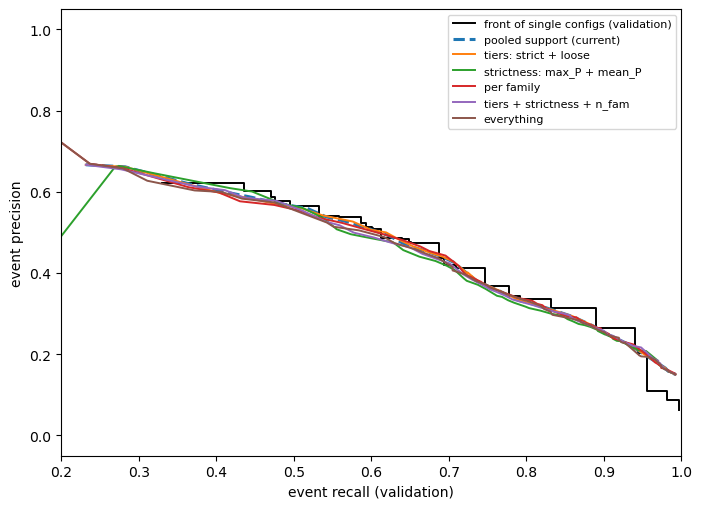

In [15]:
rs_rp = np.random.default_rng(1)
rp_scores = {n: m.predict_proba(rp_va[f])[:, 1] for n, (f, m) in rp_model.items()}
rp_yv = rp_va["label"].values
rp_rows_by_series = [np.where(rp_va["series"].values == s)[0] for s in range(len(gt_va))]
BASE = "pooled support (current)"

# series bootstrap: AUC difference to the current pooled support (paired, same resamples)
diffs = {n: [] for n in rp_scores}
for _ in range(300):
    r = np.concatenate([rp_rows_by_series[s] for s in rs_rp.integers(0, len(gt_va), len(gt_va))])
    base = roc_auc_score(rp_yv[r], rp_scores[BASE][r])
    for n, sc in rp_scores.items():
        diffs[n].append(roc_auc_score(rp_yv[r], sc[r]) - base)
for n in rp_scores:
    rp_res.loc[n, "dAUC vs pooled"] = np.mean(diffs[n])
    rp_res.loc[n, "95% CI low"], rp_res.loc[n, "95% CI high"] = np.percentile(diffs[n], [2.5, 97.5])

# event-level precision-recall curve of every feature set (thresholds = score quantiles; recall vs ALL true events)
rp_curves = {}
for n, sc in rp_scores.items():
    th = np.unique(np.quantile(sc, np.linspace(0, 1, 81)))
    rp_curves[n] = eu.event_curve(rp_va, sc, gt_va, TOL, thresholds=th).sort_values("recall")
rp_res["max F1 (event)"] = {n: c["f1"].max() for n, c in rp_curves.items()}
display(rp_res.round(3))

fig, ax = plt.subplots(figsize=(8, 5.8))
if "front_va" in globals():
    ax.step(front_va["R"], front_va["P"], where="post", c="k", lw=1.4, label="front of single configs (validation)")
for n, c in rp_curves.items():
    ax.plot(c["recall"], c["precision"], lw=2.2 if n == BASE else 1.4, ls="--" if n == BASE else "-", label=n)
ax.set_xlim(0.2, 1); ax.set_xlabel("event recall (validation)"); ax.set_ylabel("event precision"); ax.legend(fontsize=8); plt.show()

## Step 6e: scenarios, hand-picked ruptures configs, ONE logistic-regression weight per config (validation)

Instead of pooling configs into a support fraction, pick a few specific configs of the ruptures front (chosen by TRAIN precision / recall / F1 only) and give each its own 0/1 feature, so the logistic regression learns a weight per config:

| scenario | configs |
|---|---|
| best-F1 config alone | reference, no model |
| high-precision + high-recall | the config with the highest train precision and the one with the highest train recall |
| high-P + best-F1 + high-R | the two above plus the best train F1 config |
| one per family | the best train F1 config of each ruptures family (different cost functions / search methods) |
| 5 spread along the front | 5 configs evenly spaced by train recall |
| all 42, each its own feature | upper bound for a linear combination of configs |

Two modes: **A** candidates are built only from the selected configs (a real ensemble of those detectors, the candidate ceiling shrinks); **B** candidates come from all 42 configs and only the features use the selected configs (isolates the ranking, ceiling stays about 0.99). `C` and class weight are chosen on validation by ROC-AUC; the metric to compare is the best event-level F1 on validation.

In [16]:
def rp_matrix(dets, gts, cfgs):
    """Candidates built from `cfgs` only: (series/pos/label, candidate x config 0/1 matrix)."""
    M = eu.build_table([{c: d[c] for c in cfgs} for d in dets], gts, {c: c for c in cfgs}, TOL)
    return M[["series", "pos", "label"]], M[[f"support_{c}" for c in cfgs]].set_axis(cfgs, axis=1)

# roles chosen on TRAIN only
f1_tr = retained.set_index("cfg").loc[rp_cfgs, "F1"]
c_P, c_R, c_F = rp_info["P"].idxmax(), rp_info["R"].idxmax(), f1_tr.idxmax()
spread = list(rp_info.sort_values("R").index[np.linspace(0, len(rp_info) - 1, 5).round().astype(int)])
SCEN = {
    "high-precision + high-recall": [c_P, c_R],
    "high-P + best-F1 + high-R": [c_P, c_F, c_R],
    "one per family (best F1 each)": [f1_tr[ids].idxmax() for ids in rp_fam_ids.values()],
    "5 spread along the front": spread,
    "all 42, each its own feature": rp_cfgs,
}
SCEN = {k: list(dict.fromkeys(v)) for k, v in SCEN.items()}

# the chosen configs: train and validation precision / recall / F1
chosen = list(dict.fromkeys(c for v in SCEN.values() for c in v if len(v) < len(rp_cfgs)))
tab_cfg = []
for c in chosen:
    tp, fp, fn = eu.pooled_counts([d[c] for d in det_va], gt_va, TOL)
    p, r = tp / max(tp + fp, 1), tp / (tp + fn)
    tab_cfg.append(dict(cfg=c, family=rp_info.loc[c, "family"], P_train=rp_info.loc[c, "P"], R_train=rp_info.loc[c, "R"], F1_train=f1_tr[c],
                        P_val=p, R_val=r, F1_val=2 * p * r / (p + r)))
display(pd.DataFrame(tab_cfg).set_index("cfg").round(3))

def curve_for(score, table):
    u = np.unique(score)
    th = u if len(u) <= 100 else np.unique(np.quantile(score, np.linspace(0, 1, 81)))
    return eu.event_curve(table, score, gt_va, TOL, thresholds=th).sort_values("recall")

rows, sc_curves = [], {}
for name, cfgs in SCEN.items():
    for mode in ("A", "B"):
        if mode == "B" and len(cfgs) == len(rp_cfgs):
            continue
        src = cfgs if mode == "A" else rp_cfgs                                   # which configs build the candidates
        (mt, Xt), (mv, Xv) = rp_matrix(det_tr, gt_tr, src), rp_matrix(det_va, gt_va, src)
        Xt, Xv = Xt[cfgs], Xv[cfgs]
        bst = None
        for C in C_GRID:
            for cw in CLASS_WEIGHTS:
                m = LogisticRegression(C=C, class_weight=cw, max_iter=3000).fit(Xt, mt["label"])
                a = roc_auc_score(mv["label"], m.predict_proba(Xv)[:, 1])
                if bst is None or a > bst[0]:
                    bst = (a, C, cw, m)
        a, C, cw, m = bst
        sc = m.predict_proba(Xv)[:, 1]
        cu = curve_for(sc, mv); b = cu.loc[cu["f1"].idxmax()]
        sc_curves[(name, mode)] = cu
        rows.append(dict(scenario=name, mode=mode, n_configs=len(cfgs), val_candidates=len(mv), ceiling=mv["label"].sum() / n_true_va,
                         AUC=a, C=C, class_weight=str(cw), precision=b["precision"], recall=b["recall"], F1=b["f1"]))
sc_res = pd.DataFrame(rows).set_index(["scenario", "mode"])
ref_f1 = tab_cfg[[t["cfg"] for t in tab_cfg].index(c_F)]["F1_val"]
print(f"reference: best train-F1 config alone on validation F1 = {ref_f1:.3f}; pooled support of all 42 (step 6b/6d) F1 = {rp_res.loc[BASE, 'max F1 (event)']:.3f}" if "rp_res" in globals() else f"reference: best-F1 config alone F1 = {ref_f1:.3f}")
sc_res.round(3)

,family,P_train,R_train,F1_train,P_val,R_val,F1_val
cfg,,,,,,,
KernelCPD|linear|t73,KernelCPD_linear,0.625,0.401,0.457,0.623,0.287,0.393
KernelCPD|linear|t37,KernelCPD_linear,0.064,1.000,0.118,0.062,0.997,0.118
KernelCPD|linear|t59,KernelCPD_linear,0.570,0.643,0.569,0.538,0.538,0.538
Binseg|l1|t24,Binseg_l1,0.200,0.939,0.319,0.214,0.940,0.349
Binseg|l2|t53,Binseg_l2,0.112,0.985,0.190,0.087,0.982,0.160
KernelCPD|rbf|t36,KernelCPD_rbf,0.302,0.874,0.428,0.307,0.808,0.444
Pelt|l2|t15,Pelt_l2,0.601,0.578,0.557,0.587,0.471,0.522
Pelt|mahalanobis|t38,Pelt_mahalanobis,0.230,0.927,0.334,0.169,0.908,0.286
KernelCPD|linear|t115,KernelCPD_linear,0.581,0.610,0.565,0.563,0.495,0.527


reference: best train-F1 config alone on validation F1 = 0.538; pooled support of all 42 (step 6b/6d) F1 = 0.550


n_configs  val_candidates  ceiling    AUC  \
scenario                      mode                                              
high-precision + high-recall  A             2            4951    0.993  0.592   
                              B             2            5076    0.992  0.582   
high-P + best-F1 + high-R     A             3            4955    0.995  0.682   
                              B             3            5076    0.992  0.663   
one per family (best F1 each) A             6            4400    0.975  0.748   
                              B             6            5076    0.992  0.739   
5 spread along the front      A             5            4964    0.993  0.741   
                              B             5            5076    0.992  0.718   
all 42, each its own feature  A            42            5076    0.992  0.750   

                                       C class_weight  precision  recall  \
scenario                      mode                                         
high-precision + high-recall  A     0.01         None      0.606   0.280   
                              B     0.01         None      0.611   0.282   
high-P + best-F1 + high-R     A     0.01         None      0.535   0.533   
                              B     0.01         None      0.543   0.541   
one per family (best F1 each) A     0.10     balanced      0.512   0.533   
                              B     0.01     balanced      0.529   0.544   
5 spread along the front      A     0.01     balanced      0.514   0.581   
                              B     0.01         None      0.518   0.586   
all 42, each its own feature  A     0.01         None      0.529   0.573   

                                       F1  
scenario                      mode         
high-precision + high-recall  A     0.383  
                              B     0.386  
high-P + best-F1 + high-R     A     0.534  
                              B     0.542  
one per family (best F1 each) A     0.522  
                              B     0.536  
5 spread along the front      A     0.546  
                              B     0.550  
all 42, each its own feature  A     0.550

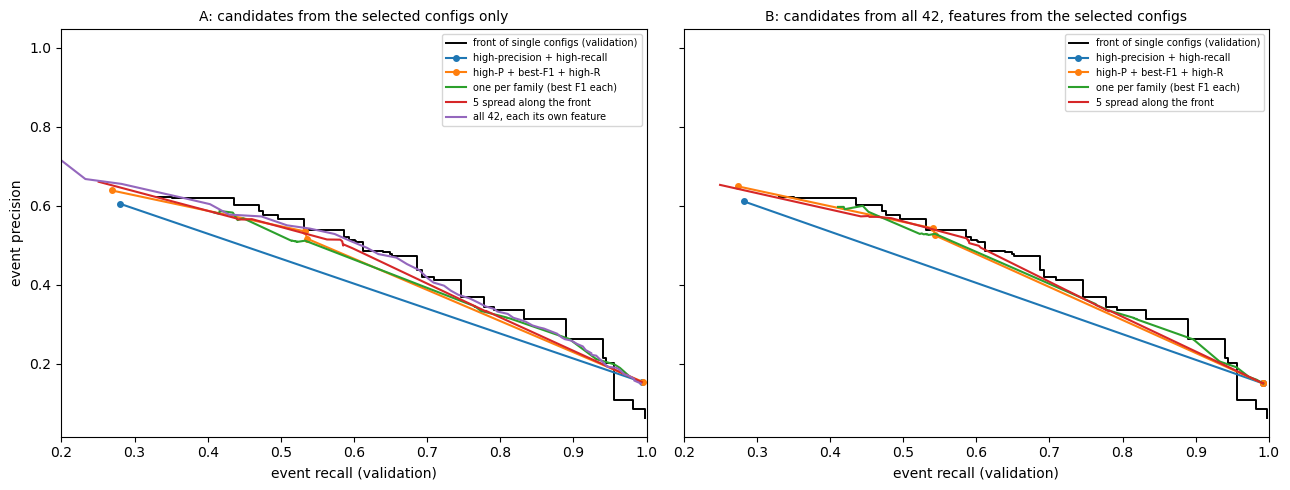

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, mode, ttl in zip(axs, ("A", "B"), ("A: candidates from the selected configs only", "B: candidates from all 42, features from the selected configs")):
    if "front_va" in globals():
        ax.step(front_va["R"], front_va["P"], where="post", c="k", lw=1.4, label="front of single configs (validation)")
    for (name, md), cu in sc_curves.items():
        if md == mode:
            ax.plot(cu["recall"], cu["precision"], marker="o" if len(cu) < 12 else None, ms=4, lw=1.5, label=name)
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("event recall (validation)"); ax.set_xlim(0.2, 1); ax.legend(fontsize=7)
axs[0].set_ylabel("event precision"); plt.tight_layout(); plt.show()

## Step 6f: scenarios with an informative high-recall config

In Step 6e the high-recall config (highest train recall, precision about 0.06) fires on almost every candidate, so its 0/1 feature is nearly constant and the logistic regression effectively had one input. Here the "high recall" member is a **mid-recall** config instead: the front config whose train recall is closest to 0.85 (`c_M`), and the best-F1 config of the KernelCPD-rbf family (`c_X`, a different cost function). Same procedure as 6e (one weight per config, modes A and B, `C` / class weight by validation AUC). Selection of the configs uses train only.

,family,P_train,R_train,F1_train,P_val,R_val,F1_val
cfg,,,,,,,
KernelCPD|linear|t73,KernelCPD_linear,0.625,0.401,0.457,0.623,0.287,0.393
KernelCPD|linear|t89,KernelCPD_linear,0.329,0.847,0.454,0.335,0.792,0.471
KernelCPD|linear|t59,KernelCPD_linear,0.570,0.643,0.569,0.538,0.538,0.538
KernelCPD|rbf|t36,KernelCPD_rbf,0.302,0.874,0.428,0.307,0.808,0.444


reference on validation: best train-F1 config alone 0.538; pooled support of all 42 0.550; all 42 as separate features 0.550


n_configs  val_candidates  ceiling  \
scenario                            mode                                       
high-P + mid-recall                 A             2            1822    0.795   
                                    B             2            5076    0.992   
high-P + best-F1 + mid-recall       A             3            1863    0.811   
                                    B             3            5076    0.992   
high-P + best-F1 + rbf              A             3            1868    0.811   
                                    B             3            5076    0.992   
high-P + best-F1 + mid-recall + rbf A             4            2238    0.866   
                                    B             4            5076    0.992   

                                          distinct_scores    AUC     C  \
scenario                            mode                                 
high-P + mid-recall                 A                   3  0.617  0.01   
                                    B                   4  0.690  0.01   
high-P + best-F1 + mid-recall       A                   7  0.696  0.01   
                                    B                   8  0.717  0.01   
high-P + best-F1 + rbf              A                   7  0.689  0.01   
                                    B                   8  0.719  0.01   
high-P + best-F1 + mid-recall + rbf A                  15  0.723  0.01   
                                    B                  16  0.737  0.10   

                                         class_weight  precision  recall  \
scenario                            mode                                   
high-P + mid-recall                 A            None      0.335   0.795   
                                    B            None      0.329   0.796   
high-P + best-F1 + mid-recall       A            None      0.537   0.533   
                                    B            None      0.537   0.542   
high-P + best-F1 + rbf              A            None      0.537   0.533   
                                    B            None      0.532   0.542   
high-P + best-F1 + mid-recall + rbf A            None      0.524   0.533   
                                    B            None      0.531   0.534   

                                             F1  
scenario                            mode         
high-P + mid-recall                 A     0.472  
                                    B     0.465  
high-P + best-F1 + mid-recall       A     0.535  
                                    B     0.539  
high-P + best-F1 + rbf              A     0.535  
                                    B     0.537  
high-P + best-F1 + mid-recall + rbf A     0.529  
                                    B     0.533

weights
scenario                            mode                                                   
high-P + mid-recall                 A     {'KernelCPD|linear|t73': 1.01, 'KernelCPD|line...
                                    B     {'KernelCPD|linear|t73': 1.04, 'KernelCPD|line...
high-P + best-F1 + mid-recall       A     {'KernelCPD|linear|t73': 0.66, 'KernelCPD|line...
                                    B     {'KernelCPD|linear|t73': 0.65, 'KernelCPD|line...
high-P + best-F1 + rbf              A     {'KernelCPD|linear|t73': 0.65, 'KernelCPD|line...
                                    B     {'KernelCPD|linear|t73': 0.65, 'KernelCPD|line...
high-P + best-F1 + mid-recall + rbf A     {'KernelCPD|linear|t73': 0.63, 'KernelCPD|line...
                                    B     {'KernelCPD|linear|t73': 0.76, 'KernelCPD|line...

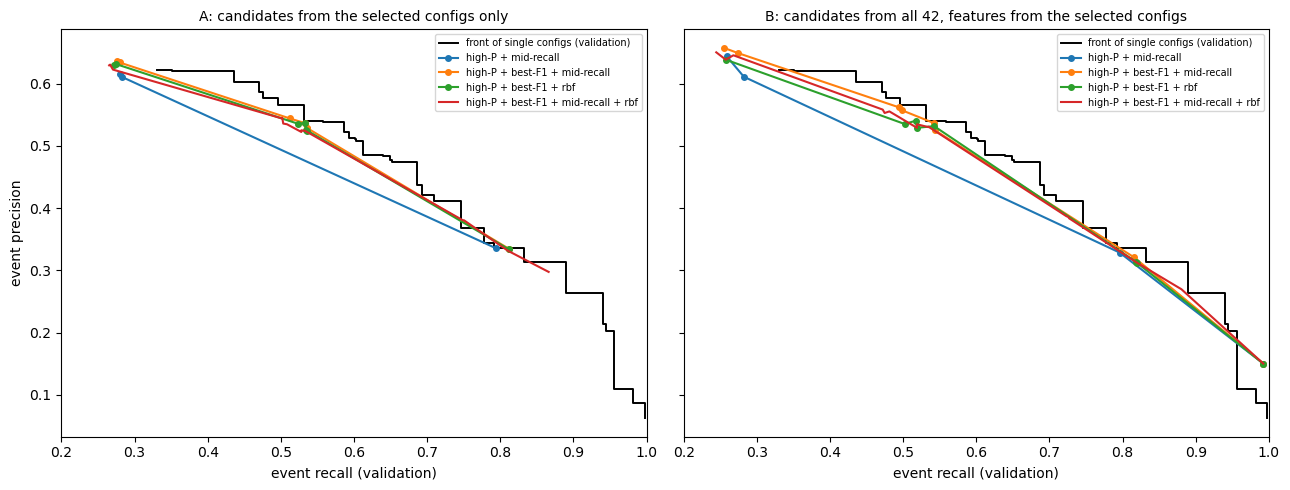

In [18]:
c_M = (rp_info["R"] - 0.85).abs().idxmin()                                      # mid-recall config (train recall closest to 0.85)
c_X = f1_tr[rp_fam_ids["KernelCPD_rbf"]].idxmax()                               # best-F1 config of a different cost function (rbf kernel)
SCEN2 = {
    "high-P + mid-recall":                  [c_P, c_M],
    "high-P + best-F1 + mid-recall":        [c_P, c_F, c_M],
    "high-P + best-F1 + rbf":               [c_P, c_F, c_X],
    "high-P + best-F1 + mid-recall + rbf":  [c_P, c_F, c_M, c_X],
}
SCEN2 = {k: list(dict.fromkeys(v)) for k, v in SCEN2.items()}
tab2 = []
for c in dict.fromkeys(c for v in SCEN2.values() for c in v):
    tp, fp, fn = eu.pooled_counts([d[c] for d in det_va], gt_va, TOL)
    p, r = tp / max(tp + fp, 1), tp / (tp + fn)
    tab2.append(dict(cfg=c, family=rp_info.loc[c, "family"], P_train=rp_info.loc[c, "P"], R_train=rp_info.loc[c, "R"], F1_train=f1_tr[c],
                     P_val=p, R_val=r, F1_val=2 * p * r / (p + r)))
display(pd.DataFrame(tab2).set_index("cfg").round(3))

rows2, curves2 = [], {}
for name, cfgs in SCEN2.items():
    for mode in ("A", "B"):
        src = cfgs if mode == "A" else rp_cfgs
        (mt, Xt), (mv, Xv) = rp_matrix(det_tr, gt_tr, src), rp_matrix(det_va, gt_va, src)
        Xt, Xv = Xt[cfgs], Xv[cfgs]
        bst = None
        for C in C_GRID:
            for cw in CLASS_WEIGHTS:
                m = LogisticRegression(C=C, class_weight=cw, max_iter=3000).fit(Xt, mt["label"])
                a = roc_auc_score(mv["label"], m.predict_proba(Xv)[:, 1])
                if bst is None or a > bst[0]:
                    bst = (a, C, cw, m)
        a, C, cw, m = bst
        sc = m.predict_proba(Xv)[:, 1]
        cu = curve_for(sc, mv); b = cu.loc[cu["f1"].idxmax()]
        curves2[(name, mode)] = cu
        rows2.append(dict(scenario=name, mode=mode, n_configs=len(cfgs), val_candidates=len(mv), ceiling=mv["label"].sum() / n_true_va,
                          distinct_scores=len(np.unique(sc.round(6))), AUC=a, C=C, class_weight=str(cw),
                          precision=b["precision"], recall=b["recall"], F1=b["f1"],
                          weights=dict(zip([c.split("|")[0] + "|" + c.split("|")[1] + "|" + c.split("|")[2] for c in cfgs], m.coef_[0].round(2)))))
sc_res2 = pd.DataFrame(rows2).set_index(["scenario", "mode"])
print(f"reference on validation: best train-F1 config alone {ref_f1:.3f}; pooled support of all 42 {rp_res.loc[BASE, 'max F1 (event)']:.3f}; all 42 as separate features {sc_res.loc[('all 42, each its own feature', 'A'), 'F1']:.3f}")
display(sc_res2.drop(columns="weights").round(3))
display(sc_res2[["weights"]])

fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, mode, ttl in zip(axs, ("A", "B"), ("A: candidates from the selected configs only", "B: candidates from all 42, features from the selected configs")):
    if "front_va" in globals():
        ax.step(front_va["R"], front_va["P"], where="post", c="k", lw=1.4, label="front of single configs (validation)")
    for (name, md), cu in curves2.items():
        if md == mode:
            ax.plot(cu["recall"], cu["precision"], marker="o" if len(cu) < 12 else None, ms=4, lw=1.5, label=name)
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("event recall (validation)"); ax.set_xlim(0.2, 1); ax.legend(fontsize=7)
axs[0].set_ylabel("event precision"); plt.tight_layout(); plt.show()

## Step 7: freeze the complete pipeline (nothing below this cell may change it)

In [19]:
configs_final = {c: p for c, p in configs.items() if group_of[c] in SEL}
group_final = {c: group_of[c] for c in configs_final}
frozen = dict(detectors=list(SEL), configs=configs_final, group_of=group_final, features=FEAT, rule=RULE,
              tolerance=TOL, candidate_window=TOL,
              preprocessing="each series standardized (zero mean, unit std); NGRIP: cut to the DO-catalog range (no padding), forward time, standardized",
              C=C_SEL, class_weight=CW_SEL, intercept=float(lr.intercept_[0]), coefficients=dict(zip(FEAT, map(float, lr.coef_[0]))),
              threshold=THRESHOLD, threshold_criterion="max event-level F1 on validation",
              validation=dict(precision=float(best["precision"]), recall=float(best["recall"]), f1=float(best["f1"]), candidate_recall=float(best["cand_recall"])))
json.dump(frozen, open(os.path.join(RESULTS, "frozen_pipeline.json"), "w"), indent=1, default=str)

ref = retained[retained["cfg"].isin(configs_final)].loc[lambda d: d["F1"].idxmax(), "cfg"]   # reference only, never used for a decision
def report(name, dets, gts):
    """Frozen pipeline on one split: candidates, ceiling, TP/FP/FN/precision/recall/F1, reference single config."""
    tb = tables(dets, gts, SEL)
    score = lr.predict_proba(tb[FEAT])[:, 1]
    prf = lambda tp, fp, fn: (tp / max(tp + fp, 1), tp / (tp + fn), 2 * tp / (2 * tp + fp + fn))
    tp, fp, fn = eu.event_counts(tb, gts, score >= THRESHOLD, TOL)
    print(f"{name}: {len(tb)} candidates, candidate recall ceiling = {tb['label'].sum() / sum(len(g) for g in gts):.3f}")
    print(f"{name}: TP={tp} FP={fp} FN={fn}  precision={prf(tp, fp, fn)[0]:.3f} recall={prf(tp, fp, fn)[1]:.3f} F1={prf(tp, fp, fn)[2]:.3f}")
    tp, fp, fn = eu.pooled_counts([d[ref] for d in dets], gts, TOL)
    print(f"reference single config {ref}: TP={tp} FP={fp} FN={fn} precision={prf(tp, fp, fn)[0]:.3f} recall={prf(tp, fp, fn)[1]:.3f}")
    return tb.assign(score=score)

## Step 8: test set, scored once (do not change anything after seeing this)

In [20]:
det_te, gt_te = eu.run_split(TEST_PATH, configs_final, os.path.join(CACHE, "test_dets.pkl"))
tab_te = report("TEST", det_te, gt_te)
print(f"validation was: precision={best['precision']:.3f} recall={best['recall']:.3f} F1={best['f1']:.3f}")

TEST: 5160 candidates, candidate recall ceiling = 0.994


TEST: TP=477 FP=525 FN=233  precision=0.476 recall=0.672 F1=0.557
reference single config KernelCPD|linear|t59: TP=427 FP=366 FN=283 precision=0.538 recall=0.601
validation was: precision=0.499 recall=0.628 F1=0.556


## Step 9: NGRIP, same frozen pipeline (cut to the DO-catalog range, no padding; forward time, standardized, warming only)

In [21]:
import ammonyte as amt
data_dir = os.path.join(os.path.dirname(amt.__file__), "data")
ngrip = amt.Series.from_csv(os.path.join(data_dir, "NGRIP.csv"))
do_age = np.sort(pd.read_csv(os.path.join(data_dir, "DO_onsets_Rasmussen2014.csv"), comment="#")["main25_kyr_b2k"].dropna().values.astype(float))
win = ngrip.slice([do_age.min(), do_age.max()])
fwd = amt.Series(time=-win.time[::-1], value=win.value[::-1], time_name="time (forward)", time_unit="-kyr b2k",
                 value_name=win.value_name, value_unit=win.value_unit, label="NGRIP fwd", verbose=False).standardize()
t_f, v_f, gt_ng = np.asarray(fwd.time, float), np.asarray(fwd.value, float), np.sort(-do_age)
det_ng = [{cid: detectors.detect_warming(t_f, v_f, c, rng=(gt_ng.min(), gt_ng.max())) for cid, c in configs_final.items()}]
tab_ng = report("NGRIP", det_ng, [gt_ng])
tab_ng["accepted"] = tab_ng["score"] >= THRESHOLD
out = tab_ng.assign(age_kyr_b2k=-tab_ng["pos"])[["age_kyr_b2k", "score", "accepted", "label"] + FEAT]
out.sort_values("age_kyr_b2k").round(3)

Time axis values sorted in ascending order
Time axis values sorted in ascending order


NGRIP: 134 candidates, candidate recall ceiling = 1.000
NGRIP: TP=20 FP=3 FN=5  precision=0.870 recall=0.800 F1=0.833
reference single config KernelCPD|linear|t59: TP=20 FP=1 FN=5 precision=0.952 recall=0.800


,age_kyr_b2k,score,accepted,label,support_LERM,support_ruptures
133,14.97,0.333,False,1,0.0,0.095
132,15.39,0.365,False,0,0.0,0.167
131,15.86,0.323,False,0,0.0,0.071
130,16.59,0.302,False,0,0.0,0.024
129,17.29,0.333,False,0,0.0,0.095
...,...,...,...,...,...,...
4,110.93,0.443,False,0,1.0,0.119
3,111.80,0.302,False,0,0.0,0.024
2,112.78,0.313,False,0,0.0,0.048
1,113.29,0.323,False,0,0.0,0.071


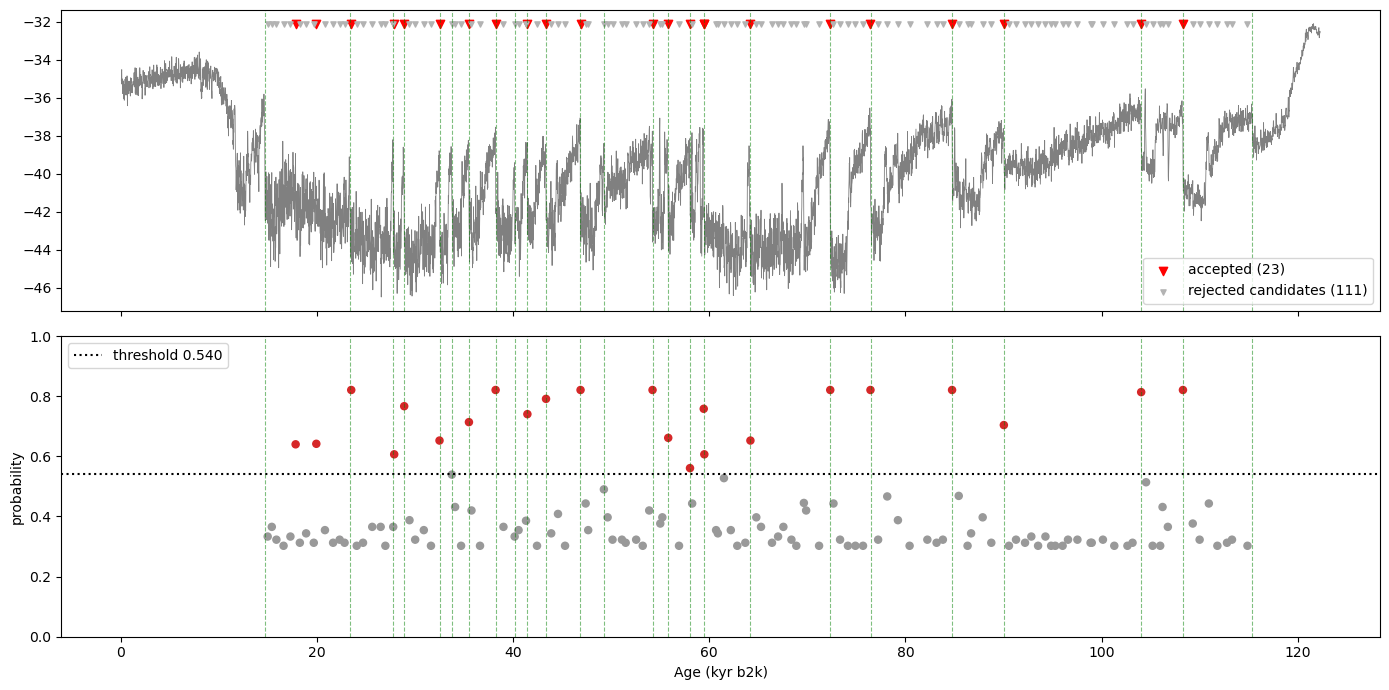

In [22]:
fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axs[0].plot(ngrip.time, ngrip.value, c="0.5", lw=.6)
a_, r_ = out[out.accepted], out[~out.accepted]
axs[0].scatter(a_.age_kyr_b2k, [ngrip.value.max()] * len(a_), c="red", marker="v", label=f"accepted ({len(a_)})")
axs[0].scatter(r_.age_kyr_b2k, [ngrip.value.max()] * len(r_), c="0.7", marker="v", s=14, label=f"rejected candidates ({len(r_)})"); axs[0].legend(loc="lower right")
axs[1].scatter(out.age_kyr_b2k, out.score, c=np.where(out.accepted, "tab:red", "0.6"), s=26); axs[1].axhline(THRESHOLD, c="k", ls=":", label=f"threshold {THRESHOLD:.3f}")
axs[1].set_ylim(0, 1); axs[1].set_ylabel("probability"); axs[1].set_xlabel("Age (kyr b2k)"); axs[1].legend()
for ax in axs:
    for t in do_age: ax.axvline(t, c="green", ls="--", lw=.8, alpha=.5)
plt.tight_layout(); plt.show()

## Step 10: NGRIP timing distribution

Each NGRIP candidate has a time and a probability (the frozen logistic regression score). Bars: the probabilities summed in 0.5 kyr bins (= tolerance), so a bar is high where several candidates agree and each has a high probability. Curve: the same candidates as a probability-weighted KDE (bandwidth = tolerance / 2). Both are normalized to area 1, so they share one axis: this shows *where in time* events are most probable relative to other times, not the probability that an event exists (that is the per-candidate score above).

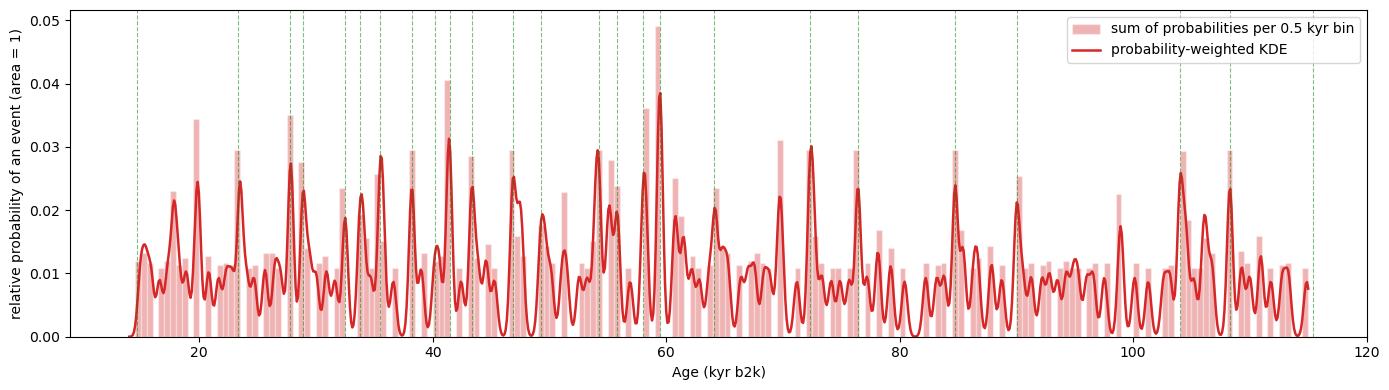

In [23]:
age, p = out["age_kyr_b2k"].values, out["score"].values
edges = np.arange(np.floor(age.min()), np.ceil(age.max()) + TOL, TOL)
grid = np.linspace(edges[0], edges[-1], 1000)
dens = eu.detection_density(age, grid, weights=p) / p.sum()      # area 1

fig, ax = plt.subplots(figsize=(14, 4))
ax.hist(age, bins=edges, weights=p, density=True, color="tab:red", alpha=.35, edgecolor="white", label="sum of probabilities per 0.5 kyr bin")
ax.plot(grid, dens, c="tab:red", lw=1.8, label="probability-weighted KDE")
for t in do_age: ax.axvline(t, c="green", ls="--", lw=.8, alpha=.5)
ax.set_xlabel("Age (kyr b2k)"); ax.set_ylabel("relative probability of an event (area = 1)"); ax.legend()
plt.tight_layout(); plt.show()

## Step 11: performance by noise colour and SNR (diagnostic, validation + test, nothing refit)

How does each method behave on white / pink / red noise at SNR = -12, -6, 0 dB (`sigma_noise = gap / k`, SNR = 20 log10 k; the manifests give colour and level per series)? Each method is represented by ONE config, the best-train-F1 config of its family (Pelt, KernelCPD, Binseg, KS, LERM), and the **Ensemble** is the frozen logistic regression with its frozen threshold. Event-level precision and recall (one-to-one matching, recall vs ALL true events), TP/FP/FN pooled over the series of each cell. Held-out data only (validation + test = 60 series, 6-8 per colour x SNR cell), so single points are noisy. The ensemble threshold was chosen on validation, so its validation half is slightly optimistic. Test is rerun with all configs (KS is not in the frozen test cache) into `results/cache/test_dets_all.pkl`.

In [ ]:
# held-out = validation + test. One representative config per method (best TRAIN F1) + the frozen ensemble. Nothing is refit.
# test is rerun with ALL configs (KS too) into a separate cache, so the frozen test cache is untouched
det_te_all, gt_te_all = eu.run_split(TEST_PATH, configs, os.path.join(CACHE, "test_dets_all.pkl"))
method_of = retained["family"].str.split("_").str[0].where(retained["detector"] == "ruptures", retained["detector"])
REP = retained.assign(method=method_of).sort_values("F1").groupby("method")["cfg"].last().to_dict()   # Pelt, KernelCPD, Binseg, KS, LERM
SNR_DB = {"k0p25": -12, "k0p5": -6, "k1": 0}          # sigma_noise = gap / k  ->  SNR = 20 log10(k) dB
rows = []
for split, det, gt in (("validation", det_va, gt_va), ("test", det_te_all, gt_te_all)):
    man = pd.read_csv(os.path.join(SPLIT_DIR, f"{split}_manifest.csv"))
    tb = tables(det, gt, SEL)
    accepted = lr.predict_proba(tb[FEAT])[:, 1] >= THRESHOLD
    for i in range(len(gt)):
        picks = {m: det[i][c] for m, c in REP.items()}
        picks["Ensemble"] = tb["pos"][(tb["series"] == i).values & accepted].values
        for m, d in picks.items():
            tp, fp, fn = eu.pooled_counts([d], [gt[i]], TOL)
            rows.append(dict(split=split, method=m, color=man["color"][i], snr_dB=SNR_DB[man["level"][i]], TP=tp, FP=fp, FN=fn))
perf = pd.DataFrame(rows)
def prf(g):    # pooled event-level precision / recall of a group of series
    s = g[["TP", "FP", "FN"]].sum()
    return pd.Series(dict(precision=s.TP / max(s.TP + s.FP, 1), recall=s.TP / (s.TP + s.FN), n_series=len(g)))
METHODS = ["Pelt", "KernelCPD", "Binseg", "KS", "LERM", "Ensemble"]
print({m: REP[m] for m in METHODS[:-1]})
for by in ("color", "snr_dB"):
    display(perf.groupby(["method", by]).apply(prf, include_groups=False)[["precision", "recall"]].unstack().reindex(METHODS).round(2))


{'Pelt': 'Pelt|l2|t15', 'KernelCPD': 'KernelCPD|linear|t59', 'Binseg': 'Binseg|l1|t24', 'KS': 'KS|t103', 'LERM': 'LERM|t131'}


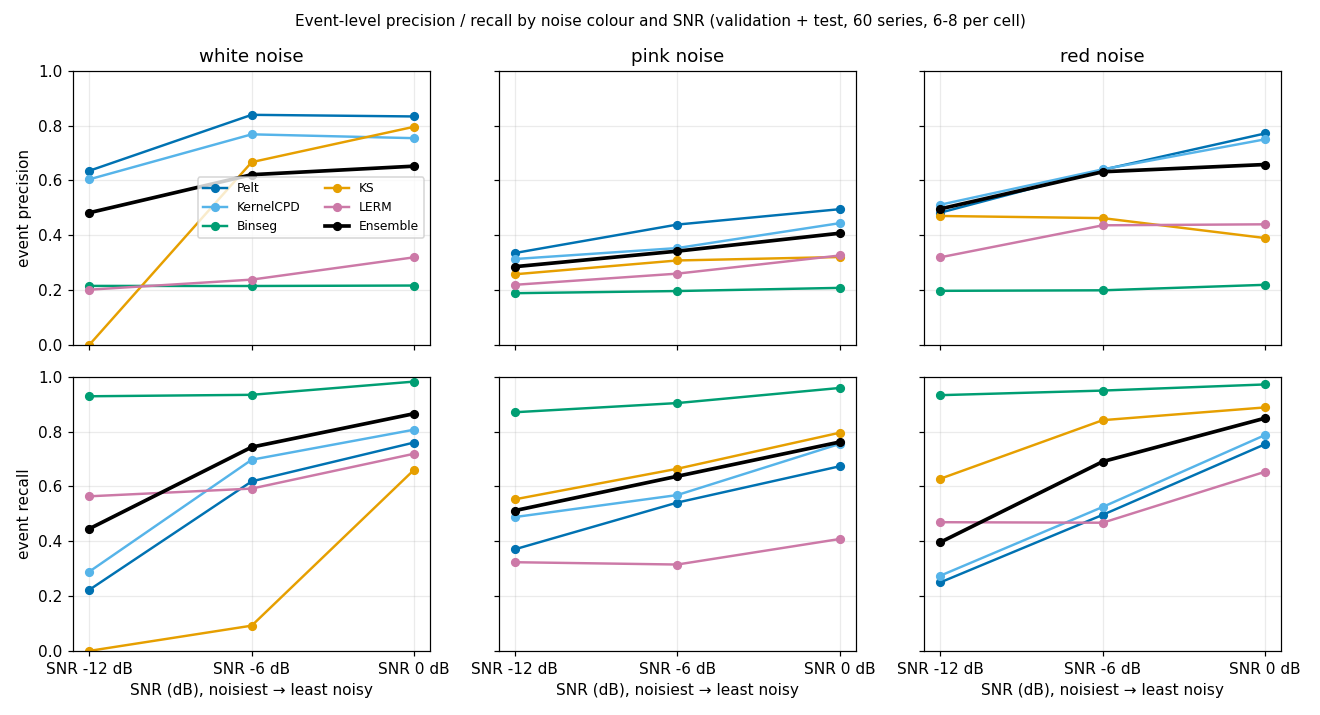

In [ ]:
cell = perf.groupby(["method", "color", "snr_dB"]).apply(prf, include_groups=False).reset_index()
COLORS = {"Pelt": "#0072B2", "KernelCPD": "#56B4E9", "Binseg": "#009E73", "KS": "#E69F00", "LERM": "#CC79A7", "Ensemble": "k"}
SNRS = sorted(SNR_DB.values())
fig, axs = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey="row")
for j, colour in enumerate(["white", "pink", "red"]):
    for i, metric in enumerate(["precision", "recall"]):
        ax = axs[i, j]
        for m in METHODS:
            d = cell[(cell["method"] == m) & (cell["color"] == colour)].set_index("snr_dB").reindex(SNRS)
            ax.plot(range(len(SNRS)), d[metric], marker="o", ms=5, lw=2.4 if m == "Ensemble" else 1.6, c=COLORS[m], label=m)
        ax.set(ylim=(0, 1), xticks=range(len(SNRS)), xticklabels=[f"SNR {s} dB" for s in SNRS]); ax.grid(alpha=.25)
        if i == 0: ax.set_title(f"{colour} noise")
        if j == 0: ax.set_ylabel(f"event {metric}")
        if i == 1: ax.set_xlabel("SNR (dB), noisiest → least noisy")
axs[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle(f"Event-level precision / recall by noise colour and SNR (validation + test, {perf.groupby('split')['TP'].size().sum() // len(METHODS)} series, 6-8 per cell)", fontsize=10)
plt.tight_layout(); plt.show()
